# Reclassifying Cities by Tourism Type

<div dir="rtl">

تعداد شهرها در `city_slug` زیاد است و بررسی تک‌تک آن‌ها برای بازار اجاره‌ی کوتاه‌مدت کمکی نمی‌کند. شهرها را بر اساس هدف اصلی سفر به ۴ گروه تقسیم می‌کنیم و بررسی می‌کنیم که آیا نوع گردشگری روی نوع اقامتگاه و قیمت آن اثر دارد یا نه.

</div>

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

cols = ['cat2_slug', 'cat3_slug', 'city_slug', 'location_latitude', 'location_longitude',
        'regular_person_capacity', 'rent_price_on_regular_days']
df = pd.read_parquet('divar_clean.parquet', columns=cols)

<div dir="rtl">

- `leisure`: سفرهای تفریحی؛ شهرهای سه استان شمالی، به‌همراه کیش، قشم، چابهار و هرمز
- `pilgrimage`: مشهد و قم
- `cultural`: اصفهان، شیراز، یزد، کاشان و تبریز
- `non_tourist`: بقیه‌ی شهرها

شهرهای استان‌های شمالی را از روی مختصات مرکز شهر جدا کرده‌ایم.

</div>

In [2]:
pilgrimage = ['mashhad', 'qom']
cultural = ['isfahan', 'shiraz', 'yazd', 'kashan', 'tabriz']
south_islands = ['kish', 'qeshm', 'chabahar', 'hormuz']

# Caspian provinces: city centre north of 36.3 and between 48.7 and 54.7 east
centers = df.groupby('city_slug')[['location_latitude', 'location_longitude']].median()
north = centers[(centers['location_latitude'] > 36.3) &
                (centers['location_longitude'].between(48.7, 54.7))].index

def tourism_type(city):
    if city in pilgrimage:
        return 'pilgrimage'
    if city in cultural:
        return 'cultural'
    if city in north or city in south_islands:
        return 'leisure'
    return 'non_tourist'

df['tourism_type'] = df['city_slug'].map(tourism_type, na_action='ignore')
df.groupby('tourism_type')['city_slug'].nunique()

tourism_type
cultural         5
leisure        129
non_tourist    285
pilgrimage       2
Name: city_slug, dtype: int64

In [3]:
daily = df[df['cat2_slug'] == 'temporary-rent'].copy()
daily['price_per_person'] = daily['rent_price_on_regular_days'] / daily['regular_person_capacity']
suites = daily[daily['cat3_slug'] == 'suite-apartment'].dropna(subset=['price_per_person'])

summary = pd.crosstab(daily['tourism_type'], daily['cat3_slug'], normalize='index') * 100
summary['ads'] = daily['tourism_type'].value_counts()
summary['suite price per person (k toman)'] = suites.groupby('tourism_type')['price_per_person'].median() / 1000
summary.round(1)

cat3_slug,suite-apartment,villa,workspace,ads,suite price per person (k toman)
tourism_type,,,,,
cultural,63.1,34.2,2.7,3936,175.0
leisure,40.9,58.7,0.3,8789,200.0
non_tourist,57.8,39.8,2.4,13786,200.0
pilgrimage,71.5,26.2,2.4,3185,125.0


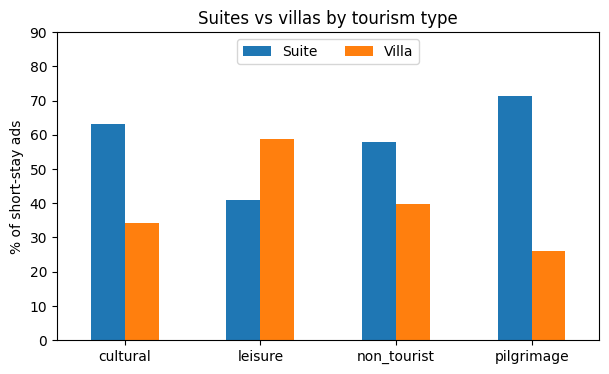

In [4]:
summary[['suite-apartment', 'villa']].plot(kind='bar', rot=0, figsize=(7, 4))
plt.ylabel('% of short-stay ads')
plt.ylim(0, 90)
plt.legend(['Suite', 'Villa'], loc='upper center', ncol=2)
plt.xlabel('')
plt.title('Suites vs villas by tourism type')
plt.show()

<div dir="rtl">

چون حجم نمونه زیاد است، p-value تقریباً همیشه خیلی کوچک می‌شود. برای قضاوت درباره‌ی اندازه‌ی اثر از Cramér's V و ε² استفاده می‌کنیم.

</div>

## H1: Tourism type and accommodation type

<div dir="rtl">

**H0:** نوع اقامتگاه (سوئیت، ویلا یا `workspace`) به نوع گردشگری شهر بستگی ندارد.

</div>

In [5]:
table = pd.crosstab(daily['tourism_type'], daily['cat3_slug'])
chi2, p, dof, expected = stats.chi2_contingency(table)
v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"chi2 = {chi2:.0f}, p-value = {p:.2g}, Cramer's V = {v:.2f}")

chi2 = 1506, p-value = 0, Cramer's V = 0.16


<div dir="rtl">

H0 رد می‌شود و اثر در حد ضعیف تا متوسط است. در شهرهای تفریحی بیشتر آگهی‌ها ویلا هستند و در شهرهای زیارتی بیشتر سوئیت.

</div>

## H2: Suite price per person

<div dir="rtl">

**H0:** قیمت هر نفر در شب برای سوئیت‌ها در هر چهار گروه یکسان است.

</div>

In [6]:
groups = [g['price_per_person'] for _, g in suites.groupby('tourism_type')]
h, p = stats.kruskal(*groups)
eps2 = (h - len(groups) + 1) / (len(suites) - len(groups))
print(f'H = {h:.0f}, p-value = {p:.2g}, epsilon squared = {eps2:.3f}')

H = 378, p-value = 1.6e-81, epsilon squared = 0.048


<div dir="rtl">

تفاوت معنادار است ولی اثر کلی ضعیف است. طبق جدول بالا، گروهی که از بقیه جدا می‌شود شهرهای زیارتی‌اند؛ پس آن‌ها را با بقیه مقایسه می‌کنیم.

</div>

In [7]:
is_pilgrimage = suites['tourism_type'] == 'pilgrimage'
u, p = stats.mannwhitneyu(suites.loc[is_pilgrimage, 'price_per_person'],
                          suites.loc[~is_pilgrimage, 'price_per_person'])
r = 1 - 2 * u / (is_pilgrimage.sum() * (~is_pilgrimage).sum())
print(f'p-value = {p:.2g}, rank-biserial r = {r:.2f}')

p-value = 4.7e-74, rank-biserial r = 0.33


## Conclusion

<div dir="rtl">

سوئیت‌های شهرهای زیارتی با اثر متوسط ارزان‌تر از بقیه‌اند. بازار اقامت کوتاه‌مدت در شهرهای تفریحی ویلامحور است و در شهرهای زیارتی سوئیت‌محور و ارزان. پس در هر نوع مقصد باید روی جذب و نمایش محصول متفاوتی تمرکز کرد، و در شهرهای زیارتی رقابت اصلی بر سر قیمت است.

</div>